## Лабораторная работа №1 - Линейная регрессия и факторный анализ

### Цель работы
Изучение основ линейной регрессии, построение простейших моделей регрессии, проведение обучения модели на реальных данных и оценка её качество.

### Задачи:
- загрузить датасет
- провести первичный анализ структуры и качества исходных данных, визуализировать распределение числовых и категориальных признаков, а также целевой переменной
- выполнить предварительную обработку данных
- исследовать корреляционные связи между признаками
- определить наличие мультиколлинеарности с помощью коэффициента VIF
- разделить данные на обучающую и тестовую выборки
- построить модели линейной, гребневой и лассо-регрессии
- оценить качество построенных моделей по метрикам RMSE, R² и MAPE, провести кросс-валидацию моделей
- исследовать остатки построенных моделей и определить наличие признаков гомоскедастичности или гетероскедастичности
- выполнить стандартизацию признаков и снижение размерности методом главных компонент (PCA);
- определить количество главных компонент с использованием графика каменистой осыпи;
- повторно построить модели линейной, гребневой и лассо-регрессии с использованием главных компонент;
- сравнить качество моделей, построенных на исходных признаках и после применения PCA;


### Описание датасета
Для проведения исследования выбран открытый датасет Diamonds, с сайта Kaggle. Датасет содержит сведения о характеристиках бриллиантов и их стоимости.

Исходный набор данных содержит 53 940 наблюдений и 10 признаков. Каждый объект представляет один бриллиант, для которого указаны его физические характеристики, качественные характеристики и цена.

В качестве целевой переменной для построения регрессионных моделей выбрана переменная __price__, представляющая стоимость бриллианта. Остальные признаки рассматриваются в качестве факторов, которые могут оказывать влияние на стоимость.

__Признаки:__
- carat - масса бриллианта в каратах (числовая)
- cut - качество огранки (категориальная)
- color - цвет бриллианта (категориальная)
- clarity - чистота бриллианта (категориальная)
- depth - глубина бриллианта в процентах (числовая)
- table - ширина площадки бриллианта в процентах (числовая)
- price - стоимость бриллианта (числовая)
- x - длина бриллианта в миллиметрах (числовая)
- y - ширина бриллианта в миллиметрах (числовая)
- z - глубина бриллианта в миллиметрах (числовая)

In [691]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.decomposition import PCA
from sklearn.model_selection import cross_validate

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    mean_absolute_percentage_error
)


Для выполнения первичного анализа и визуализации данных используются библиотеки Python pandas, numpy, matplotlib и seaborn.
Библиотека pandas используется для загрузки и обработки табличных данных. numpy применяется для выполнения численных операций. Библиотеки matplotlib и seaborn используются для построения и оформления графиков.

In [692]:
df = pd.read_csv("diamonds.csv")
df = df.drop(columns=["Unnamed: 0"])

В исходном наборе данных присутствовал столбец Unnamed: 0, содержащий индексы наблюдений. Данный столбец не характеризует свойства бриллианта и не имеет содержательного значения для построения регрессионной модели. Поэтому перед дальнейшим анализом он был удалён из набора данных.

### Первичный анализ

In [693]:
print("Размер исходного датасета:", df.shape)
df = df.iloc[:3000].copy()
print("Размер датасета после сокращения:", df.shape)

print("\nИнформация о датасете:")
print(df.info())

df.head()

Размер исходного датасета: (53940, 10)
Размер датасета после сокращения: (3000, 10)

Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    3000 non-null   float64
 1   cut      3000 non-null   object 
 2   color    3000 non-null   object 
 3   clarity  3000 non-null   object 
 4   depth    3000 non-null   float64
 5   table    3000 non-null   float64
 6   price    3000 non-null   int64  
 7   x        3000 non-null   float64
 8   y        3000 non-null   float64
 9   z        3000 non-null   float64
dtypes: float64(6), int64(1), object(3)
memory usage: 234.5+ KB
None


,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Исходный набор данных содержит 53 940 строк и 10 столбцов. Для сокращения вычислительной нагрузки и обеспечения удобства проведения экспериментов из исходного набора данных были отобраны первые 3000 наблюдений.

С помощью метода info() была исследована структура исходного набора данных. Для каждого признака определены количество непустых наблюдений и тип данных.

В таблице представлены как количественные характеристики бриллиантов (carat, depth, table, x, y, z), так и категориальные характеристики (cut, color, clarity). price используется в качестве целевой переменной при построении регрессионных моделей.

In [694]:
print("\nОсновные статистические характеристики:")
df.describe()


Основные статистические характеристики:


,carat,depth,table,price,x,y,z
count,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,0.733057,61.830467,57.591767,2739.121000,5.724310,5.724963,3.536783
std,0.189506,1.648649,2.362033,793.568209,0.570902,0.558901,0.371214
min,0.200000,53.000000,51.000000,326.000000,3.790000,3.750000,0.000000
25%,0.700000,61.000000,56.000000,2827.000000,5.680000,5.700000,3.500000
50%,0.730000,61.800000,57.000000,2963.000000,5.800000,5.815000,3.580000
75%,0.820000,62.700000,59.000000,3137.000000,6.020000,6.010000,3.720000
max,1.520000,69.700000,70.000000,3303.000000,7.560000,7.420000,4.780000


In [695]:
print("Количество пропущенных значений:")
print(df.isnull().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

Количество пропущенных значений:
carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

Количество дубликатов:
7


Для оценки качества исходных данных была выполнена проверка набора данных на наличие пропущенных значений и дубликатов. 
Так как пропущенные значения в исходном датасете отсутствуют, то не требуется выполнять заполнение пропусков или удаление строк, содержащих отсутствующие значения.

In [696]:
print("Количество нулевых значений в размерных характеристиках:")

print("x:", (df["x"] == 0).sum())
print("y:", (df["y"] == 0).sum())
print("z:", (df["z"] == 0).sum())

Количество нулевых значений в размерных характеристиках:
x: 0
y: 0
z: 2


На рисунке 1 представлено распределение целевой переменной price, характеризующей стоимость бриллиантов в долларах

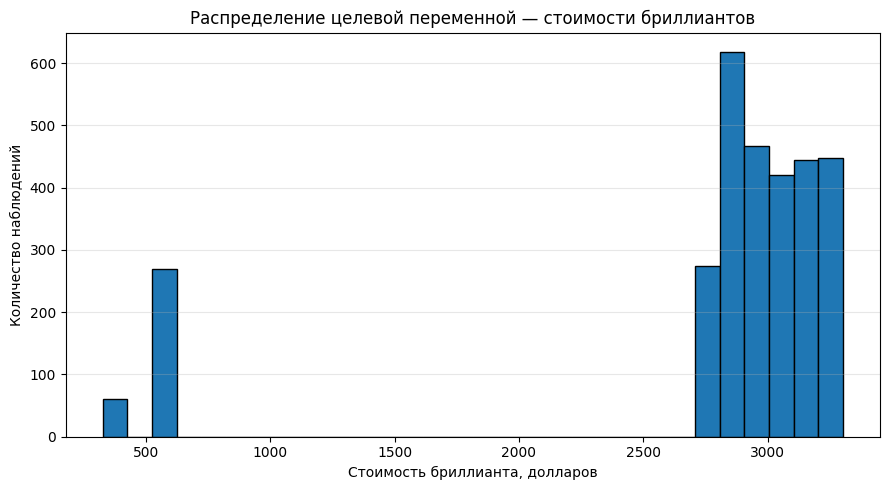

In [697]:
plt.figure(figsize=(9, 5))

plt.hist(df["price"], bins=30, edgecolor="black")

plt.title("Распределение целевой переменной — стоимости бриллиантов")
plt.xlabel("Стоимость бриллианта, долларов")
plt.ylabel("Количество наблюдений")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

<center>Рисунок 1 — График целевой переменной price</center>

На рисунке 2 представлено распределение основных числовых признаков датасета: carat, depth, table, x, y и z

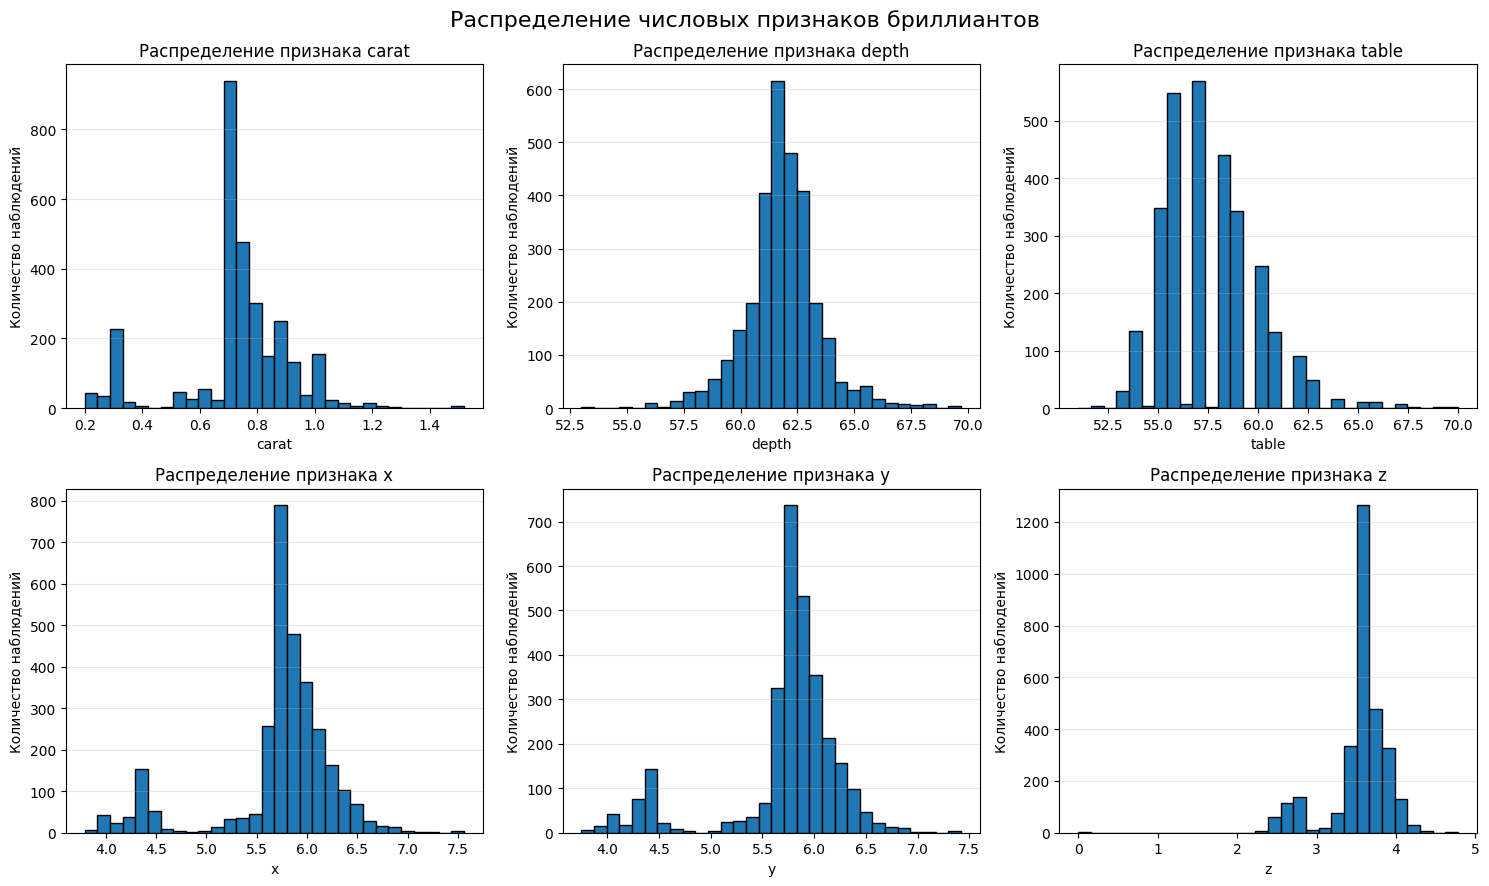

In [698]:
numeric_features = ["carat", "depth", "table", "x", "y", "z"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, feature in zip(axes.flatten(), numeric_features):
    ax.hist(
        df[feature],
        bins=30,
        edgecolor="black"
    )
    ax.set_title(f"Распределение признака {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Количество наблюдений")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Распределение числовых признаков бриллиантов",
    fontsize=16
)

plt.tight_layout()
plt.show()

<center>Рисунок 2 - Графики числовых признаков</center>

На рисунке 3 представлено распределение категориальных признаков cut, color и clarity. 

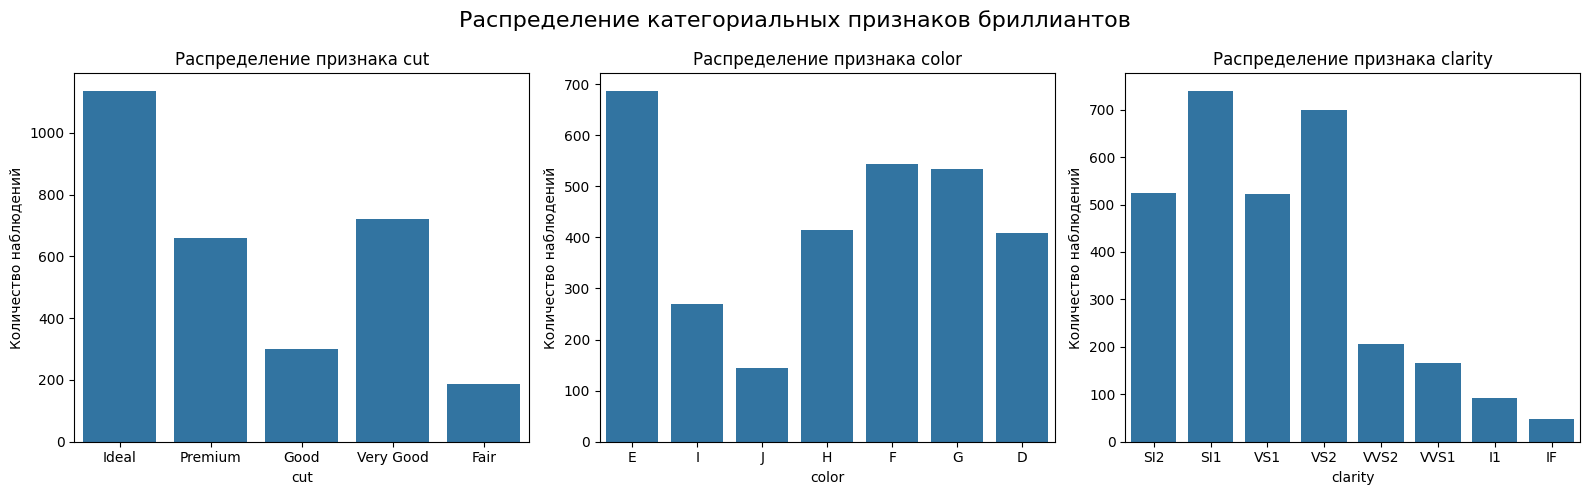

In [699]:
categorical_features = ["cut", "color", "clarity"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, categorical_features):
    sns.countplot(
        data=df,
        x=feature,
        ax=ax
    )

    ax.set_title(f"Распределение признака {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Количество наблюдений")

plt.suptitle(
    "Распределение категориальных признаков бриллиантов",
    fontsize=16
)

plt.tight_layout()
plt.show()

<center>Рисунок 3 - Графики категориальных признаков</center>

### Предобработка данных

In [700]:
print("Размер данных до удаления дубликатов:", df.shape)

df = df.drop_duplicates().copy()

print("Размер данных после удаления дубликатов:", df.shape)

Размер данных до удаления дубликатов: (3000, 10)
Размер данных после удаления дубликатов: (2993, 10)


В результате первичного анализа в наборе данных было обнаружено 7 дубликатов. Поскольку повторное присутствие одинаковых наблюдений может повлиять на результаты обучения модели, дублирующиеся строки были удалены.

In [701]:
print("Размер данных до удаления некорректных значений:", df.shape)

df = df[
    (df["x"] > 0) &
    (df["y"] > 0) &
    (df["z"] > 0)
].copy()

print("Размер данных после удаления некорректных значений:", df.shape)

Размер данных до удаления некорректных значений: (2993, 10)
Размер данных после удаления некорректных значений: (2991, 10)


Также было выявлено два наблюдения с нулевым значением признака __z__, характеризующего высоту бриллианта. Поскольку нулевая высота физически невозможна для существующего бриллианта, данные наблюдения были признаны некорректными и удалены из набора данных.

Чтобы закодировать категориальные переменные cut, color и clarity используем pd.get_dummies(). Каждая категория представлена отдельным бинарным признаком, принимающим значения 0 или 1.

In [702]:
df_encoded = pd.get_dummies(
    df,
    columns=["cut", "color", "clarity"],
    drop_first=True,
    dtype=int
)

print("Размер данных после кодирования:")
print(df_encoded.shape)

print("\nНазвания столбцов:")
print(df_encoded.columns.tolist())

print("\nПервые 5 строк:")
display(df_encoded.head())

Размер данных после кодирования:
(2991, 24)

Названия столбцов:
['carat', 'depth', 'table', 'price', 'x', 'y', 'z', 'cut_Good', 'cut_Ideal', 'cut_Premium', 'cut_Very Good', 'color_E', 'color_F', 'color_G', 'color_H', 'color_I', 'color_J', 'clarity_IF', 'clarity_SI1', 'clarity_SI2', 'clarity_VS1', 'clarity_VS2', 'clarity_VVS1', 'clarity_VVS2']

Первые 5 строк:


,carat,depth,table,price,x,y,z,cut_Good,cut_Ideal,cut_Premium,...,color_H,color_I,color_J,clarity_IF,clarity_SI1,clarity_SI2,clarity_VS1,clarity_VS2,clarity_VVS1,clarity_VVS2
0,0.23,61.5,55.0,326,3.95,3.98,2.43,0,1,0,...,0,0,0,0,0,1,0,0,0,0
1,0.21,59.8,61.0,326,3.89,3.84,2.31,0,0,1,...,0,0,0,0,1,0,0,0,0,0
2,0.23,56.9,65.0,327,4.05,4.07,2.31,1,0,0,...,0,0,0,0,0,0,1,0,0,0
3,0.29,62.4,58.0,334,4.20,4.23,2.63,0,0,1,...,0,1,0,0,0,0,0,1,0,0
4,0.31,63.3,58.0,335,4.34,4.35,2.75,1,0,0,...,0,0,1,0,0,1,0,0,0,0


### Корреляционный анализ

Для исследования взаимосвязей между основными количественными признаками была рассчитана матрица парных коэффициентов корреляции. В анализ включены шесть числовых факторов (carat, depth, table, x, y, z) и целевая переменная price.

Корреляционный коэффициент характеризует направление и силу линейной связи между двумя переменными и принимает значения от −1 до 1. 

На рисунке 4 представлена тепловая карта матрицы корреляций числовых признаков.

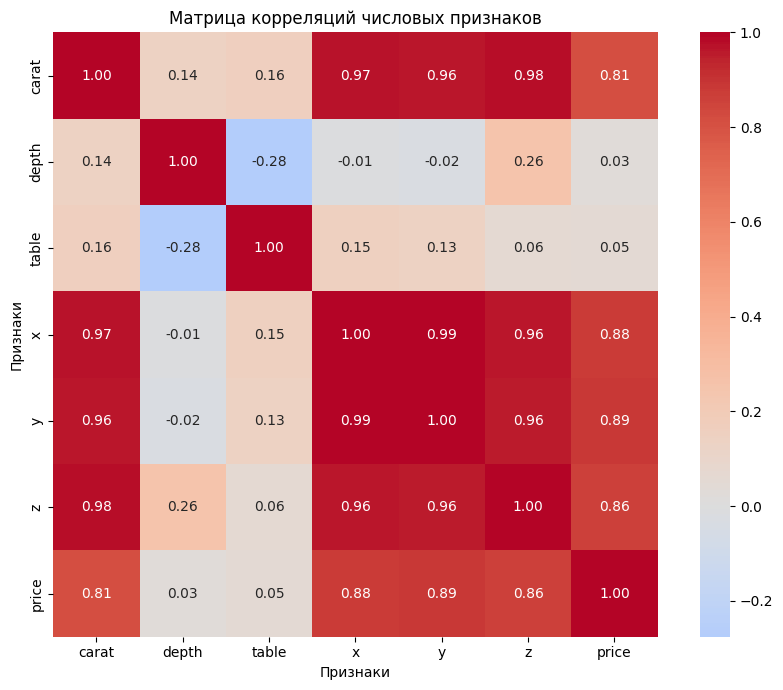

In [703]:
correlation_matrix = df[
    ["carat", "depth", "table", "x", "y", "z", "price"]
].corr()


plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Матрица корреляций числовых признаков")
plt.xlabel("Признаки")
plt.ylabel("Признаки")

plt.tight_layout()
plt.show()

<center>Рисунок 4 - Матрица корреляций</center>

По результатам анализа установлена сильная положительная корреляция между массой бриллианта carat и его геометрическими размерами: коэффициенты корреляции с признаками x, y и z составляют 0,97, 0,96 и 0,98 соответственно. Также выявлена очень сильная взаимосвязь между самими размерными характеристиками: корреляция между x и y равна 0,99, между x и z — 0,96, между y и z — 0,96.

Целевая переменная price имеет сильную положительную связь с размерными характеристиками: коэффициенты корреляции с x, y и z составляют 0,88, 0,89 и 0,86 соответственно. Корреляция цены с массой carat равна 0,81. Это указывает на наличие выраженной линейной взаимосвязи между стоимостью бриллианта, его массой и размерами.

Для количественной оценки мультиколлинеарности независимых числовых признаков был рассчитан фактор инфляции дисперсии (VIF).

In [704]:
vif_features = [
    "carat",
    "depth",
    "table",
    "x",
    "y",
    "z"
]

X_vif = add_constant(df[vif_features])

vif_data = pd.DataFrame({
    "Признак": vif_features,
    "VIF": [
        variance_inflation_factor(X_vif.values, i + 1)
        for i in range(len(vif_features))
    ]
})

vif_data = vif_data.sort_values(
    by="VIF",
    ascending=False
)

display(vif_data.round(2))

,Признак,VIF
5,z,469.63
3,x,258.68
4,y,139.21
0,carat,40.40
1,depth,36.42
2,table,1.28


Наибольшие значения показателя получены для признаков z (469,63), x (258,68) и y (139,21). Для признаков carat и depth значения VIF составили 40,40 и 36,42 соответственно. Данные результаты указывают на выраженную мультиколлинеарность между рядом независимых переменных. Для признака table значение показателя составило 1,28, что свидетельствует о несущественной мультиколлинеарности с остальными рассматриваемыми факторами.

### Регрессионные модели

__Разделение данных и обучение моделей__

Для построения регрессионных моделей исходный набор данных был разделён на матрицу независимых признаков (X) и целевую переменную (y). В качестве независимых признаков использовались шесть числовых характеристик бриллиантов (carat, depth, table, x, y, z) и три категориальных признака (cut, color, clarity). Целевой переменной является price, отражающая стоимость бриллианта.

Разделение данных на тренировочную и тестовую выборки выполнено функцией train_test_split(). В качестве параметра test_size задано значение 0,2, поэтому 80 % наблюдений используются для обучения моделей, а 20 % — для проверки качества прогнозирования.

Для предварительной обработки данных использована функция ColumnTransformer(). Числовые признаки стандартизируются с помощью StandardScaler(), а категориальные преобразуются в числовой формат методом OneHotEncoder().

Для обучения моделей был создан словарь models, содержащий три алгоритма: LinearRegression() - линейную регрессию без регуляризации, Ridge(alpha=1.0) - регрессию с L2-регуляризацией и Lasso(alpha=0.1, max_iter=20000) - регрессию с L1-регуляризацией. Параметр alpha задаёт силу регуляризации, а max_iter определяет максимальное количество итераций алгоритма Lasso.

In [705]:
numeric_features = ["carat", "depth", "table", "x", "y", "z"]
categorical_features = ["cut", "color", "clarity"]

X = df[numeric_features + categorical_features].copy()
y = df["price"]

print("Размер матрицы признаков:", X.shape)
print("Размер целевой переменной:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Размер исходной выборки:", X.shape)
print("Размер тренировочной выборки:", X_train.shape)
print("Размер тестовой выборки:", X_test.shape)
print("Количество числовых признаков:", len(numeric_features))
print("Количество категориальных признаков:", len(categorical_features))

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"),
     categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=20000)
}

pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler(with_mean=False)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline


Размер матрицы признаков: (2991, 9)
Размер целевой переменной: (2991,)
Размер исходной выборки: (2991, 9)
Размер тренировочной выборки: (2392, 9)
Размер тестовой выборки: (599, 9)
Количество числовых признаков: 6
Количество категориальных признаков: 3


__Метрики качества и кросс-валидация__

Качество построенных моделей оценивалось с помощью RMSE, коэффициента детерминации (R^2) и MAPE. Метрики были рассчитаны на тестовой выборке, которая не использовалась при обучении моделей. Дополнительно проведена пятикратная кросс-валидация на тренировочных данных для проверки устойчивости результатов.

In [706]:
results = []

for name, pipeline in pipelines.items():
    y_pred = pipeline.predict(X_test)

    results.append({
        "Модель": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R²": r2_score(y_test, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100
    })

results_df = pd.DataFrame(results).round(3)
display(results_df.sort_values("RMSE"))

cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
    "MAPE": "neg_mean_absolute_percentage_error"
}

cv_results = []

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv, scoring=scoring, n_jobs=-1
    )

    cv_results.append({
        "Модель": name,
        "Средний RMSE": -scores["test_RMSE"].mean(),
        "Средний R²": scores["test_R2"].mean(),
        "Средний MAPE, %": -scores["test_MAPE"].mean() * 100
    })

cv_results_df = pd.DataFrame(cv_results).round(3)
display(cv_results_df)

,Модель,RMSE,R²,"MAPE, %"
1,Ridge,209.726,0.934,9.068
2,Lasso,224.232,0.925,9.069
0,Linear Regression,236.543,0.917,9.088


,Модель,Средний RMSE,Средний R²,"Средний MAPE, %"
0,Linear Regression,199.512,0.935,8.633
1,Ridge,199.286,0.935,8.526
2,Lasso,199.742,0.935,8.594


На тестовой выборке наилучший результат по значениям RMSE и R^2 показала гребневая модель: RMSE составил 209,726, а R^2 - 0,934. Значение MAPE для данной модели составило 9,068%.

Результаты пятикратной кросс-валидации показали, что качество трёх моделей находится примерно на одном уровне. Средние значения R^2 после округления составили 0,935 для каждой модели. При этом Ridge продемонстрировала наименьшие средние значения RMSE и MAPE среди рассмотренных алгоритмов.

__Построение графиков остатков__

Для проверки характера ошибок прогнозирования были построены графики остатков для линейной регрессии, гребневой и лассо (рис. 5). Остатки рассчитывались как разность между фактическими и предсказанными значениями стоимости бриллиантов. 

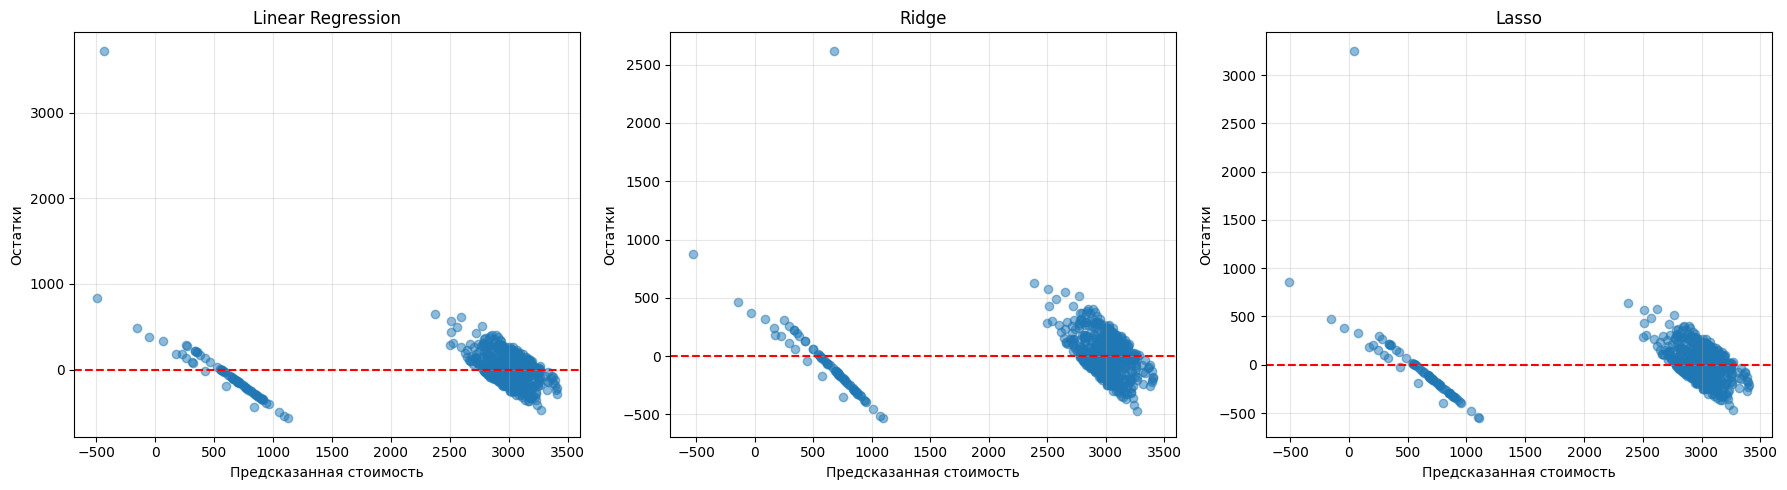

In [707]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, pipeline) in zip(axes, pipelines.items()):
    y_pred = pipeline.predict(X_test)
    residuals = y_test - y_pred

    ax.scatter(y_pred, residuals, alpha=0.5)
    ax.axhline(y=0, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_xlabel("Предсказанная стоимость")
    ax.set_ylabel("Остатки")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

<center>Рисунок 5 - Графики остатков</center>

_Анализ остатков регрессионных моделей:_

Основная масса наблюдений сосредоточена в области предсказанных значений от примерно 2500 до 3500, при этом разброс остатков в этой области достаточно заметный.

Для всех трёх моделей большая часть остатков располагается около нулевой линии, что говорит об отсутствии выраженного постоянного смещения прогнозов в одну сторону. При этом распределение точек нельзя назвать полностью случайным. Особенно заметна определённая структура остатков при небольших предсказанных значениях.

Также на графиках присутствуют отдельные наблюдения с большими по абсолютной величине остатками. Это означает, что для некоторых бриллиантов модели дают значительно менее точные прогнозы.

По графикам можно предположить, что разброс ошибок изменяется в зависимости от величины предсказанной стоимости, поэтому имеются признаки гетероскедастичности.

__Устранение мультиколлинеарности и применение РСА__

In [708]:
pca_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False
    ), categorical_features)
])

X_train_pca = pca_preprocessor.fit_transform(X_train)
X_test_pca = pca_preprocessor.transform(X_test)

print("Количество признаков до PCA:", X_train_pca.shape[1])


pca = PCA()

X_train_components = pca.fit_transform(X_train_pca)
X_test_components = pca.transform(X_test_pca)

explained_variance = np.cumsum(
    pca.explained_variance_ratio_
)

print("Количество компонент:", X_train_components.shape[1])

n_components_95 = np.argmax(
    explained_variance >= 0.95
) + 1

print("Количество компонент для сохранения 95% дисперсии:",
      n_components_95)

print("Сохранённая дисперсия:",
      round(explained_variance[n_components_95 - 1] * 100, 2), "%")



Количество признаков до PCA: 23
Количество компонент: 23
Количество компонент для сохранения 95% дисперсии: 12
Сохранённая дисперсия: 95.5 %


Для устранения мультиколлинеарности и снижения размерности признакового пространства применён метод главных компонент (PCA). Перед выполнением PCA числовые признаки были стандартизированы с использованием StandardScaler, а категориальные признаки преобразованы в числовой вид методом One-Hot Encoding.
После предварительной обработки исходное пространство признаков содержит 23 признака. Метод PCA преобразует их в 23 главные компоненты, представляющие собой новые взаимно некоррелированные признаки.

Для определения необходимого количества компонент рассчитана накопленная доля объяснённой дисперсии. В качестве критерия выбрано сохранение не менее 95 % исходной дисперсии данных. Согласно полученному результату, для достижения данного порога достаточно использовать 12 главных компонент.
При этом первые 12 компонент сохраняют 95,5 % дисперсии исходных признаков. 

На графике каменистой осыпи (рис. 6) показана доля дисперсии, которую объясняет каждая главная компонента

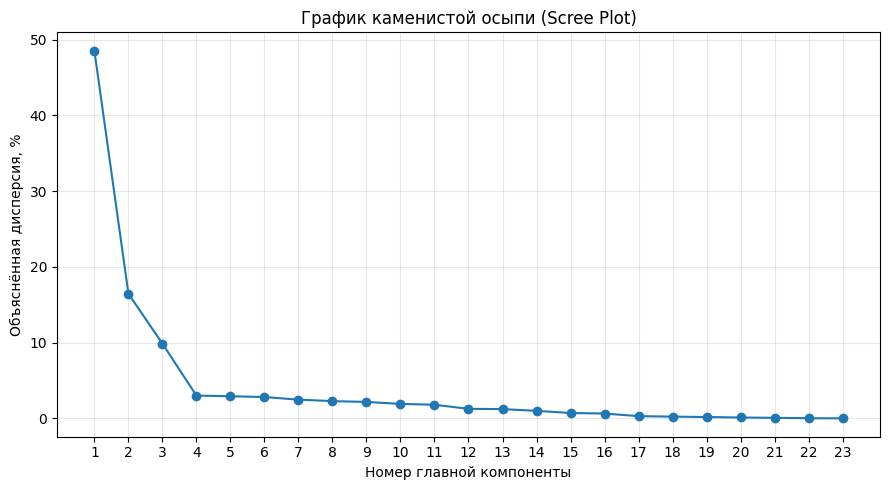

In [709]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_ * 100,
    marker="o"
)

plt.title("График каменистой осыпи (Scree Plot)")
plt.xlabel("Номер главной компоненты")
plt.ylabel("Объяснённая дисперсия, %")
plt.xticks(range(1, len(pca.explained_variance_ratio_) + 1))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

<center>Рисунок 6 - График каменистой осыпи</center>

По графику видно, что первые главные компоненты объясняют наибольшую долю дисперсии, после чего вклад последующих компонент постепенно уменьшается. 

На рисунке 7 представлена накопленная доля объяснённой дисперсии в зависимости от количества главных компонент. Для выбора размерности преобразованного пространства использован порог 95%.

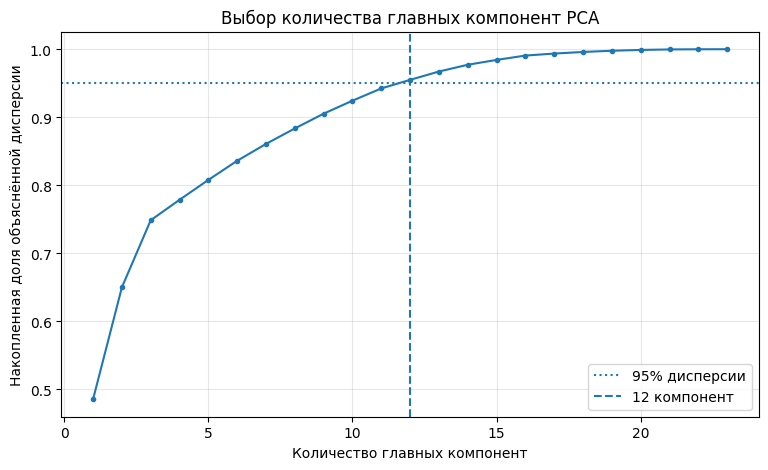

In [710]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o",
    markersize=3
)

plt.axhline(
    0.95,
    linestyle=":",
    label="95% дисперсии"
)

plt.axvline(
    n_components_95,
    linestyle="--",
    label=f"{n_components_95} компонент"
)

plt.xlabel("Количество главных компонент")
plt.ylabel("Накопленная доля объяснённой дисперсии")
plt.title("Выбор количества главных компонент PCA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

<center>Рисунок 7 - Выбор количества главных компонент методом PCA</center>

Горизонтальная линия соответствует выбранному порогу 95 %. Как видно из графика, данный порог достигается при использовании 12 главных компонент, при этом сохраняется 95,58 % дисперсии исходных данных. Поэтому дальнейшее построение регрессионных моделей выполняется с использованием 12 компонент вместо исходных 23 признаков.

__Обучение регрессионных моделей на главных компонентах__

После снижения размерности были повторно обучены модели линейной регрессии, гребневой и лассо. В отличие от предыдущего этапа, в качестве независимых переменных использовались не исходные признаки, а выбранные главные компоненты PCA, сохраняющие не менее 95% исходной дисперсии.
Для каждой модели рассчитаны RMSE, R^2 и MAPE на тестовой выборке.

In [711]:
pca_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=20000)
}

pca_results = []

X_train_pca_final = X_train_components[:, :n_components_95]
X_test_pca_final = X_test_components[:, :n_components_95]

for name, model in pca_models.items():
    model.fit(X_train_pca_final, y_train)

    y_pred = model.predict(X_test_pca_final)

    pca_results.append({
        "Модель": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R²": r2_score(y_test, y_pred),
        "MAPE, %": mean_absolute_percentage_error(y_test, y_pred) * 100
    })

pca_results_df = pd.DataFrame(pca_results).round(3)

display(pca_results_df.sort_values("RMSE"))

,Модель,RMSE,R²,"MAPE, %"
2,Lasso,317.709,0.850,15.057
1,Ridge,317.729,0.849,15.058
0,Linear Regression,317.754,0.849,15.053


_Анализ результатов регрессионных моделей на главных компонентах_

После выполнения PCA были повторно обучены три регрессионные модели: линейная, гребневая и лассо. В качестве входных признаков использовались первые 12 главных компонент, сохраняющие 95,5 % исходной дисперсии.

По результатам тестирования значения RMSE для всех трёх моделей находятся практически на одном уровне и составляют около 317,7. Наименьшее значение RMSE получено для модели лассо - 317,709, однако различие с гребневой и линейной регрессией является незначительным.

Значение коэффициента детерминации R² = 0,849 и 0,850 для моделей показывает, что модели объясняют около 85 % вариации стоимости объектов тестовой выборки.

Значения MAPE также находятся на близком уровне - около 15,05 %. Минимальное значение MAPE получено для линейной регрессии - 15,053 %, поэтому по данному показателю она имеет незначительное преимущество.

_Сравнение качества моделей до и после PCA_

Для оценки влияния снижения размерности результаты моделей на главных компонентах были сопоставлены с результатами моделей, построенных на исходных признаках. Сравнение выполнено по RMSE, R^2 и MAPE.

In [712]:
original_results = results_df.copy()
original_results["Признаки"] = "Исходные"

pca_results = pca_results_df.copy()
pca_results["Признаки"] = "Главные компоненты PCA"

comparison_df = pd.concat(
    [original_results, pca_results],
    ignore_index=True
)

comparison_df = comparison_df[
    ["Модель", "Признаки", "RMSE", "R²", "MAPE, %"]
]

display(
    comparison_df.sort_values(
        ["Модель", "Признаки"]
    ).reset_index(drop=True)
)

,Модель,Признаки,RMSE,R²,"MAPE, %"
0,Lasso,Главные компоненты PCA,317.709,0.850,15.057
1,Lasso,Исходные,224.232,0.925,9.069
2,Linear Regression,Главные компоненты PCA,317.754,0.849,15.053
3,Linear Regression,Исходные,236.543,0.917,9.088
4,Ridge,Главные компоненты PCA,317.729,0.849,15.058
5,Ridge,Исходные,209.726,0.934,9.068


Модели, использующие исходные признаки, демонстрируют более высокое качество прогнозирования по всем рассматриваемым метрикам. Для гребневой модели RMSE снизился с 317,729 при использовании главных компонент до 209,726 при использовании исходных признаков. Аналогично для линейной и лассо.

Значение R² для моделей на исходных признаках составляет около 0,917–0,934, тогда как после применения PCA оно снижается до 0,849-0,85. Это означает, что исходные признаки позволяют моделям объяснить большую часть вариации стоимости.

Аналогичная ситуация наблюдается по MAPE. Для моделей на исходных признаках ошибка составляет около 9,068–9,088 %, в то время как после применения PCA она увеличивается примерно до 15,05 %.

Для проверки устойчивости результатов после применения PCA проведена пятикратная кросс-валидация:

In [713]:
pca_pipelines = {}

for name, model in pca_models.items():
    pca_pipelines[name] = Pipeline([
        ("preprocessor", pca_preprocessor),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95)),
        ("model", model)
    ])

cv_results_pca = []

for name, pipeline in pca_pipelines.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    cv_results_pca.append({
        "Модель": name,
        "Средний RMSE": -scores["test_RMSE"].mean(),
        "Средний R²": scores["test_R2"].mean(),
        "Средний MAPE, %": -scores["test_MAPE"].mean() * 100
    })

cv_results_pca_df = pd.DataFrame(cv_results_pca).round(3)

display(cv_results_pca_df)

,Модель,Средний RMSE,Средний R²,"Средний MAPE, %"
0,Linear Regression,292.972,0.861,11.709
1,Ridge,292.972,0.861,11.714
2,Lasso,292.973,0.861,11.714


_Анализ результатов кросс-валидации_

Средние значения RMSE для всех трёх моделей практически совпадают и составляют около 292,972.

Среднее значение R² также одинаково для всех моделей и составляет 0,861, что свидетельствует о близком качестве моделей при различных разбиениях обучающей выборки.

Значения среднего MAPE находятся в диапазоне 11,709–11,714 %, поэтому различия между моделями также являются незначительными. Минимальное среднее RMSE получено для линейной и гребневой модели - 292,972.

__<center>ЗАКЛЮЧЕНИЕ</center>__

В ходе лабораторной работы были изучены основные этапы построения и оценки регрессионных моделей на реальных данных. Для исследования использовался датасет Diamonds, содержащий сведения о характеристиках и стоимости бриллиантов. Из исходного набора данных были отобраны первые 3000 наблюдений.
На этапе первичного анализа были изучены структура данных, статистические характеристики и распределения признаков. В ходе предобработки удалены 7 дубликатов и 2 наблюдения с некорректными значениями геометрических размеров. После очистки в наборе осталось 2991 наблюдение. Категориальные признаки были преобразованы в числовой формат, а числовые признаки стандартизированы.

Корреляционный анализ и расчёт коэффициентов VIF показали наличие сильной мультиколлинеарности между массой и геометрическими размерами бриллиантов. Наибольшие значения VIF получены для признаков z (469,63), x (258,68) и y (139,21).

Для прогнозирования стоимости бриллиантов были построены три модели: линейная регрессия, гребневая и лассо. Их качество оценивалось с помощью RMSE, R² и MAPE. Дополнительно была проведена пятикратная кросс-валидация и выполнен анализ остатков. По графикам остатков выявлены отдельные большие ошибки прогнозирования и признаки гетероскедастичности.

Для устранения мультиколлинеарности и снижения размерности признаков был применён метод главных компонент (PCA). В результате количество признаков сократилось с 23 до 12 при сохранении 95,5 % исходной дисперсии.

Полученные результаты показали, что устранение мультиколлинеарности и сокращение количества признаков не всегда приводят к повышению точности прогнозирования. Для рассматриваемого набора данных наиболее эффективным из исследованных вариантов оказалось использование гребневой регрессии на исходных признаках.